In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

df = pd.read_csv('/Users/Dejmen/Desktop/Ironhack/week5/Day1/amz_uk_price_prediction_dataset.csv')


print(df.info())
print(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB
None
   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound comp

In [30]:
# 1 Create a crosstab between the product category and the isBestSeller status.

best_seller_crosstab = pd.crosstab(df['category'], df['isBestSeller'], margins=False)
best_seller_crosstab['best_seller_proportion'] = best_seller_crosstab[True] / (best_seller_crosstab[True] + best_seller_crosstab[False])
best_seller_crosstab = best_seller_crosstab.sort_values('best_seller_proportion', ascending=False)

best_seller_crosstab

isBestSeller,False,True,best_seller_proportion
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
...,...,...,...
"CD, Disc & Tape Players",8798,0,0.000000
General Music-Making Accessories,259,0,0.000000
Snowboard Boots,1449,0,0.000000


In [31]:
# 2 Statistical Tests:

chi2, p, dof, expected = chi2_contingency(pd.crosstab(df['category'], df['isBestSeller']))

print(f"Chi2 statistic: {chi2:.2f}")
print(f"P-value: {p:.4f}")

if p < 0.05:
    print("Conclusion: Significant relationship between category and best-seller status.")
else:
    print("Conclusion: No significant relationship between category and best-seller status.")

Chi2 statistic: 36540.20
P-value: 0.0000
Conclusion: Significant relationship between category and best-seller status.


In [37]:
# 3 visualisations

category_status = pd.crosstab(df['Product Category'], df['Best-Seller Status'])

category_status.plot(kind='bar', stacked=True, figsize=(10, 6), color=['#1f77b4', '#ff7f0e'])
plt.title('Product Categories vs. Best-Seller Status')
plt.xlabel('Product Category')
plt.ylabel('Number of Products')
plt.xticks(rotation=45)
plt.legend(title='Best-Seller Status')
plt.tight_layout()
plt.show()

KeyError: 'Product Category'

In [39]:
# part 2
# 0

Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

df_no_outliers.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.115963e+06,2.115963e+06,2.115963e+06,2.115963e+06,2.115963e+06
mean,1.374141e+06,2.275402e+00,5.205211e+02,2.340827e+01,2.970697e+01
std,8.169684e+05,2.193863e+00,6.233481e+03,2.051335e+01,2.579316e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589495e+05,0.000000e+00,0.000000e+00,9.130000e+00,0.000000e+00
50%,1.347315e+06,3.400000e+00,1.000000e+00,1.599000e+01,0.000000e+00
75%,2.067576e+06,4.400000e+00,7.500000e+01,2.999000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,9.999000e+01,5.000000e+04


In [44]:
print(df.columns)

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')


In [45]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


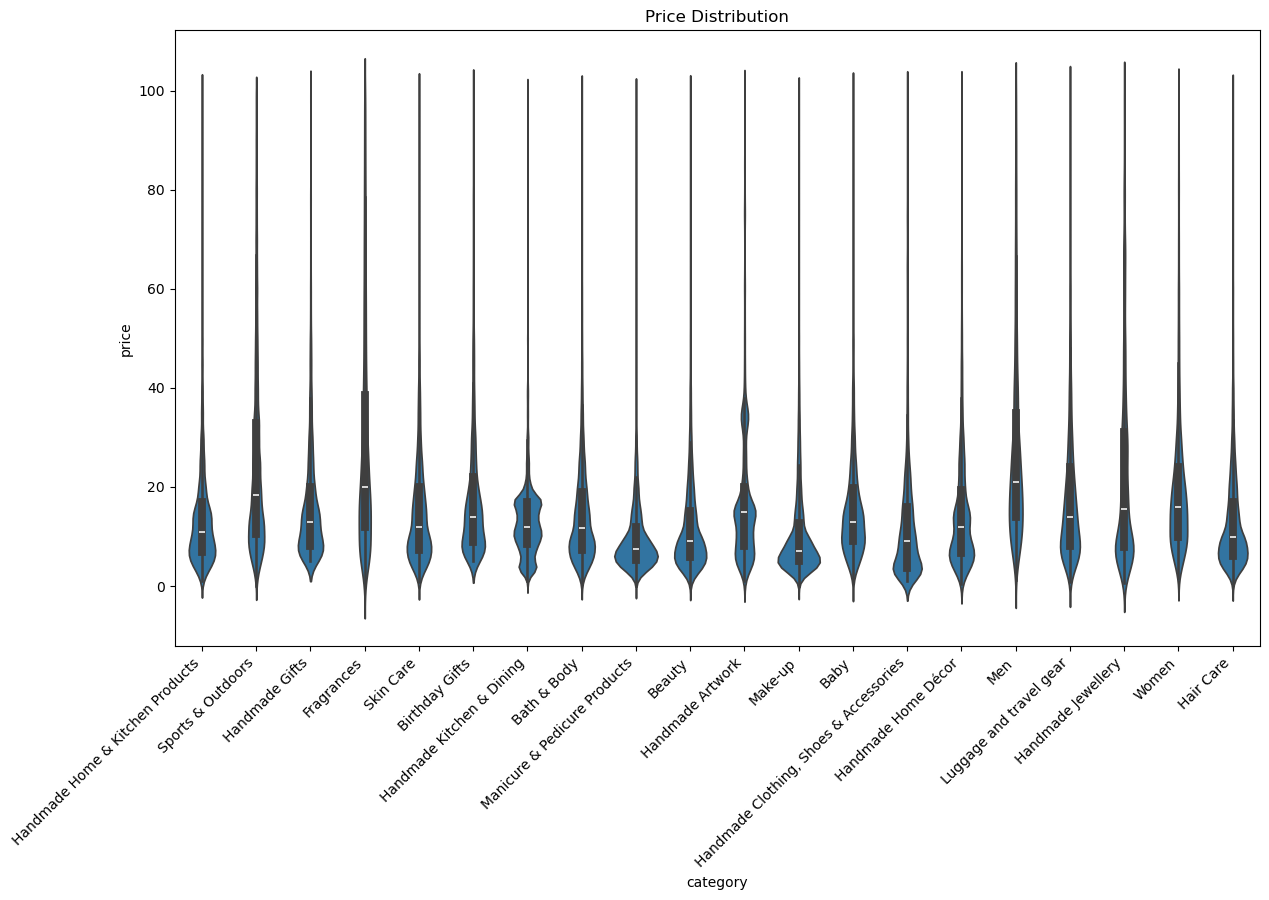

In [49]:
# 1 violin

top_categories = df_no_outliers['category'].value_counts().nlargest(20).index
df_filtered = df_no_outliers[df_no_outliers['category'].isin(top_categories)]

plt.figure(figsize=(14, 8))
sns.violinplot(x='category', y='price', data=df_filtered)
plt.title('Price Distribution')
plt.xticks(rotation=45, ha='right')
plt.show()

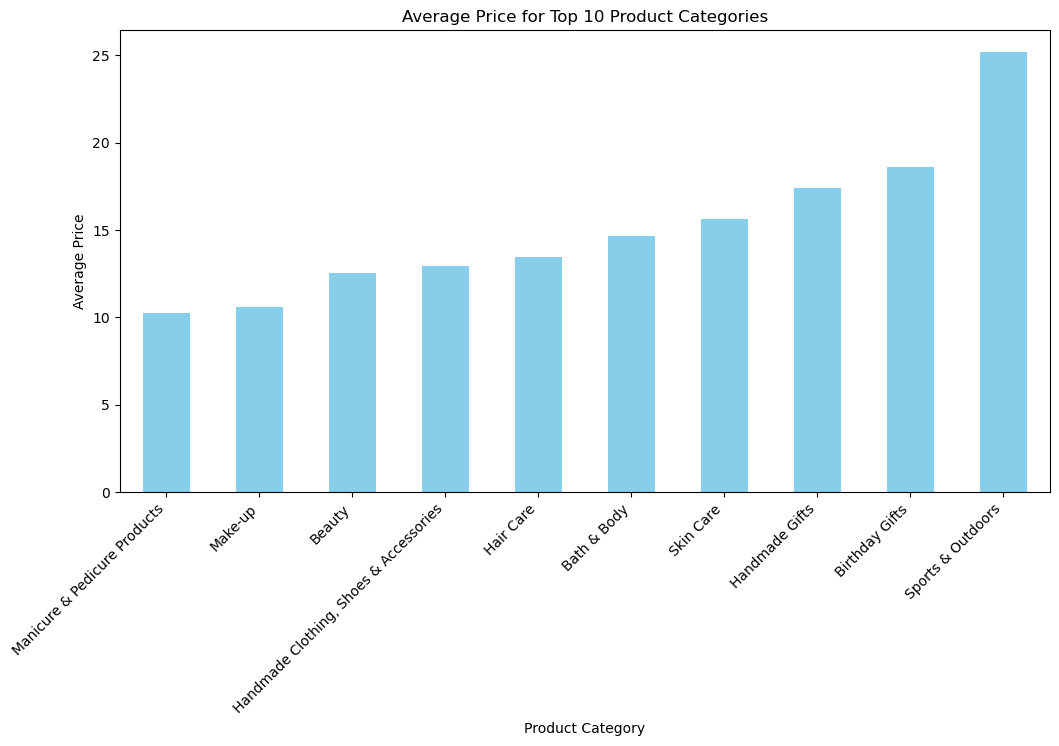

In [51]:
# 2 bar charts

avg_price_by_category = df_no_outliers.groupby('category')['price'].mean()

top_10_categories = df_no_outliers['category'].value_counts().nlargest(10).index

avg_price_top_10 = avg_price_by_category[top_10_categories]

plt.figure(figsize=(12, 6))
avg_price_top_10.sort_values().plot(kind='bar', color='skyblue')
plt.title('Average Price for Top 10 Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Average Price')
plt.xticks(rotation=45, ha='right')
plt.show()

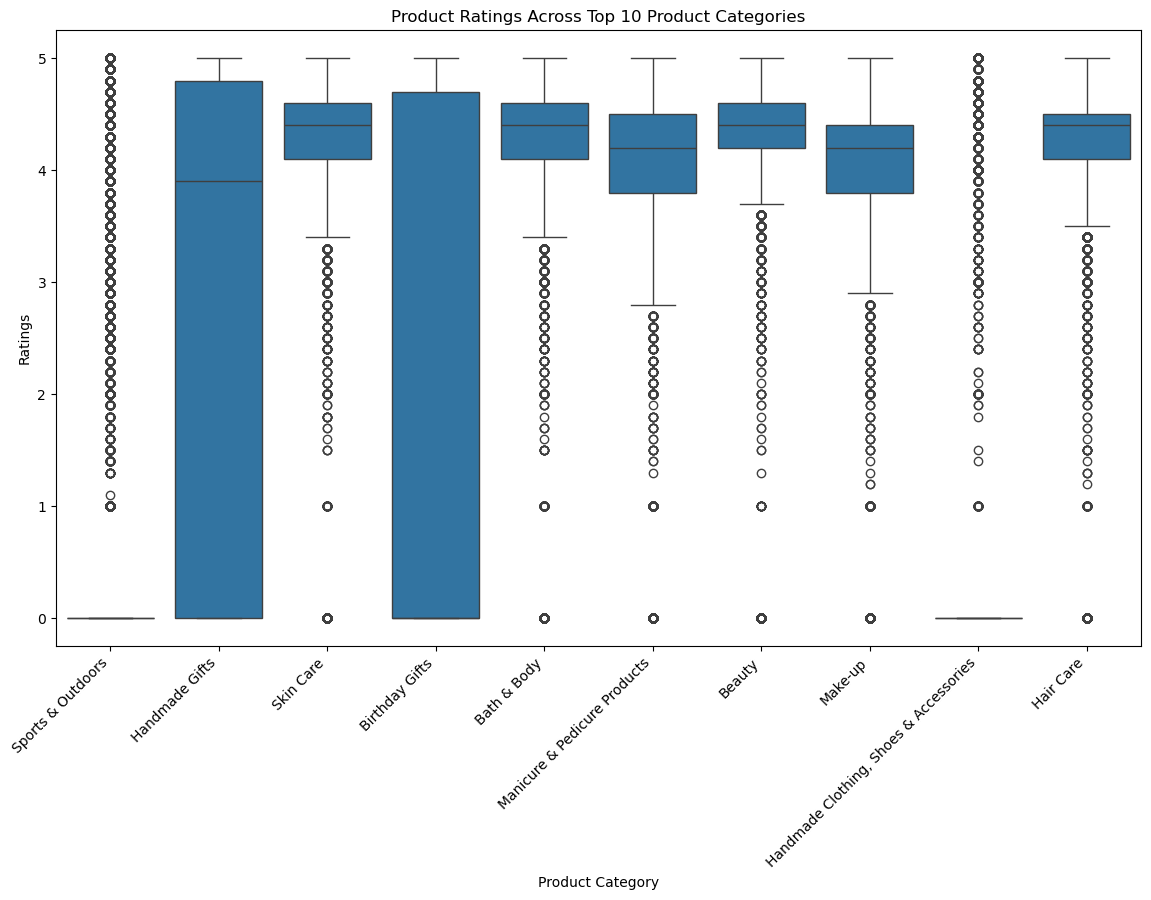

In [53]:
# 3 

top_10_categories = df_no_outliers['category'].value_counts().nlargest(10).index

df_filtered_top_10 = df_no_outliers[df_no_outliers['category'].isin(top_10_categories)]

plt.figure(figsize=(14, 8))
sns.boxplot(x='category', y='stars', data=df_filtered_top_10)
plt.title('Product Ratings Across Top 10 Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Ratings')
plt.xticks(rotation=45, ha='right')
plt.show()

In [58]:
# part 3
#1
correlation_coefficient = df_no_outliers[['price', 'stars']].corr().iloc[0, 1]
correlation_coefficient

-0.07767299878181261

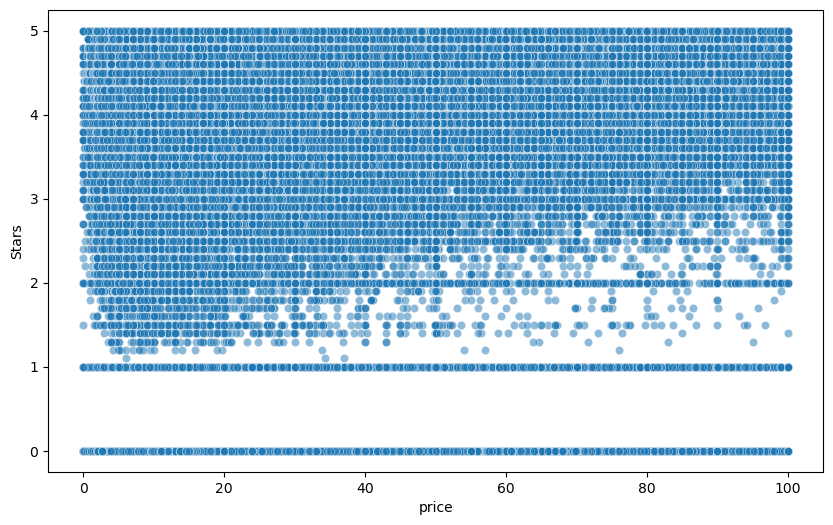

In [61]:
# 2
plt.figure(figsize=(10, 6))
sns.scatterplot(x='price', y='stars', data=df_no_outliers, alpha=0.5)
plt.ylabel('Stars')
plt.show()